In [7]:
#Download the Twitter sentiment dataset
%pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashankkumarranjan/twitter-sentiment")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'twitter-sentiment' dataset.
Path to dataset files: /kaggle/input/twitter-sentiment


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files = os.listdir(path)
print("Files in dataset directory:", files)

Files in dataset directory: ['Twitter_Data.csv']


In [9]:
#Load data and perform simple EDA
csv_files = [f for f in files if f.endswith(".csv")]

if csv_files:
    csv_path = os.path.join(path, csv_files[0])

    try:
        df = pd.read_csv(csv_path, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(csv_path, encoding="latin-1")

    print("Dataset shape:", df.shape)
    print("\nDataset Columns and Info:")
    df.info()

    print("\nFirst 5 rows:")
    display(df.head())
else:
    print("No CSV file found in the dataset folder.")

Dataset shape: (162980, 2)

Dataset Columns and Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162980 entries, 0 to 162979
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   clean_text  162976 non-null  object 
 1   category    162973 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.5+ MB

First 5 rows:


,clean_text,category
0,when modi promised “minimum government maximum...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0


Target column set to: 'category'

Class counts:
category
 1.0    72250
 0.0    55213
-1.0    35510
 NaN        7
Name: count, dtype: int64


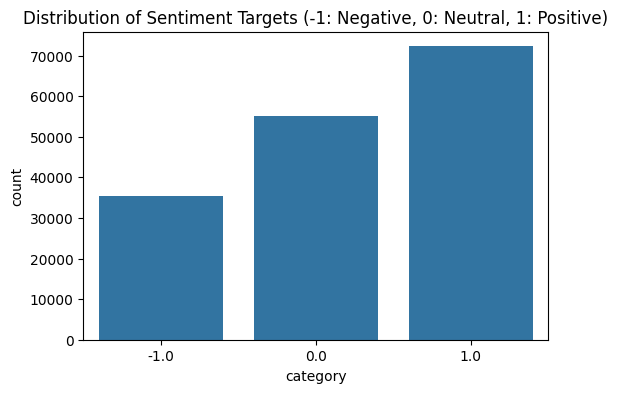

In [10]:
#Analyze sentiment distribution
target_col = "category"

print(f"Target column set to: '{target_col}'")
print("\nClass counts:")
print(df[target_col].value_counts(dropna=False))

plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df.dropna(subset=[target_col]))
plt.title("Distribution of Sentiment Targets (-1: Negative, 0: Neutral, 1: Positive)")
plt.show()

In [11]:
#Simple sentiment analysis using TF-IDF and Logistic Regression

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

text_col = "clean_text"
target_col = "category"

sample_df = df.dropna(subset=[text_col, target_col])
sample_df = sample_df.sample(n=min(20000, len(sample_df)), random_state=42)

X = sample_df[text_col]
y = sample_df[target_col].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

y_pred = model.predict(X_test_vec)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.7675

              precision    recall  f1-score   support

        -1.0       0.81      0.55      0.66       918
         0.0       0.73      0.85      0.79      1358
         1.0       0.78      0.82      0.80      1724

    accuracy                           0.77      4000
   macro avg       0.78      0.74      0.75      4000
weighted avg       0.77      0.77      0.76      4000

